In [1]:
import importlib.util
import sys
import numpy as np
import matplotlib.pyplot as plt


file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\EDMD.py"

spec = importlib.util.spec_from_file_location("edmd", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["edmd"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\ULAM.py"

spec = importlib.util.spec_from_file_location("ulam", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["ulam"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Packages\function_dictionary.py"

spec = importlib.util.spec_from_file_location("function_dictionary", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["function_dictionary"] = module
spec.loader.exec_module(module)

file_path = r"C:\Users\wagne\OneDrive\Dokumente\Universität\Master_Elektrotechnik\3.Semester\Forschungspraktikum\Code\K_PF_time_homogeneous_Markovian_RDS\Problems\Double_Well.py"

spec = importlib.util.spec_from_file_location("Double_Well", file_path)
module = importlib.util.module_from_spec(spec)
sys.modules["Double_Well"] = module
spec.loader.exec_module(module)

## Double Well

In [2]:
DW = module.Double_Well(sigma=0.7, h=1e-3, N=10000)

In [3]:
# number of trajectories
M = 10000

# random initial conditions
rng = np.random.default_rng(42)
X = rng.uniform(-2, 2, size=(M, 2))

# simulate
Y = DW.simulate(X, seed=123)

# time axis
t = np.arange(DW.N + 1) * DW.h

#### Visualize Potential

C:\Users\wagne\AppData\Local\Temp\ipykernel_28272\2490727779.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


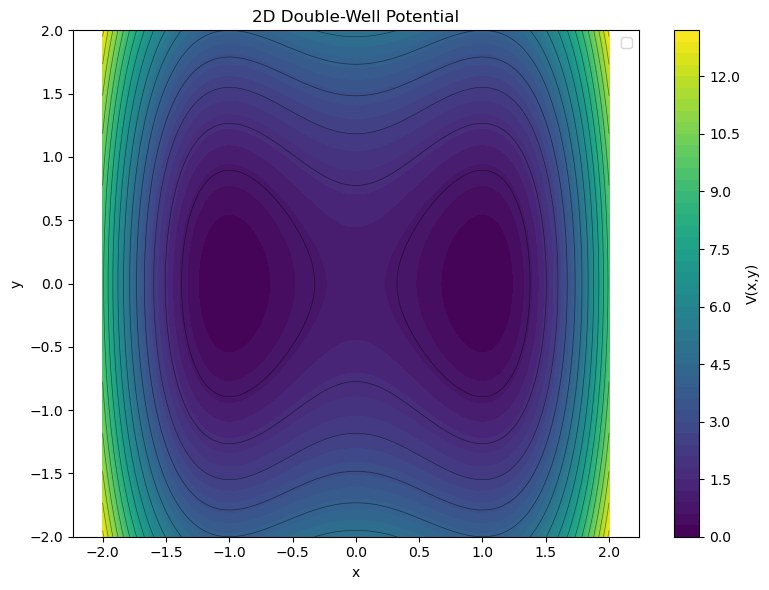

In [4]:
# grid
x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)

Xg, Yg = np.meshgrid(x, y)

# potential
Vg = (Xg**2 - 1)**2 + Yg**2

# ============================================================
# 2D contour plot
# ============================================================

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    Xg,
    Yg,
    Vg,
    levels=50,
    cmap='viridis'
)

# contour lines
plt.contour(
    Xg,
    Yg,
    Vg,
    levels=20,
    colors='black',
    linewidths=0.5,
    alpha=0.5
)


plt.title('2D Double-Well Potential')
plt.xlabel('x')
plt.ylabel('y')

plt.axis('equal')
plt.colorbar(contour, label='V(x,y)')
plt.legend()

plt.tight_layout()
plt.show()

#### Visualize Trajectories

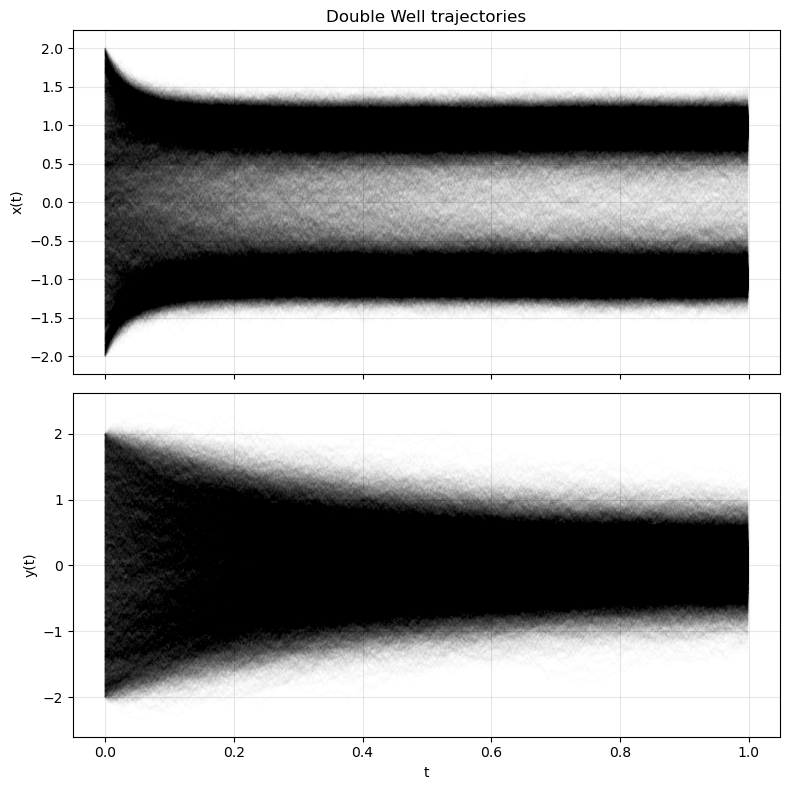

In [5]:

# time axis
t = np.arange(Y.shape[0]/10-1) * DW.h

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# X trajectories
axes[0].plot(t, Y[:1000, :, 0], lw=1, alpha=0.01, color='black')
axes[0].set_ylabel("x(t)")
axes[0].set_title("Double Well trajectories")
axes[0].grid(alpha=0.3)

# Y trajectories
axes[1].plot(t, Y[:1000, :, 1], lw=1, alpha=0.01, color='black')
axes[1].set_xlabel("t")
axes[1].set_ylabel("y(t)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

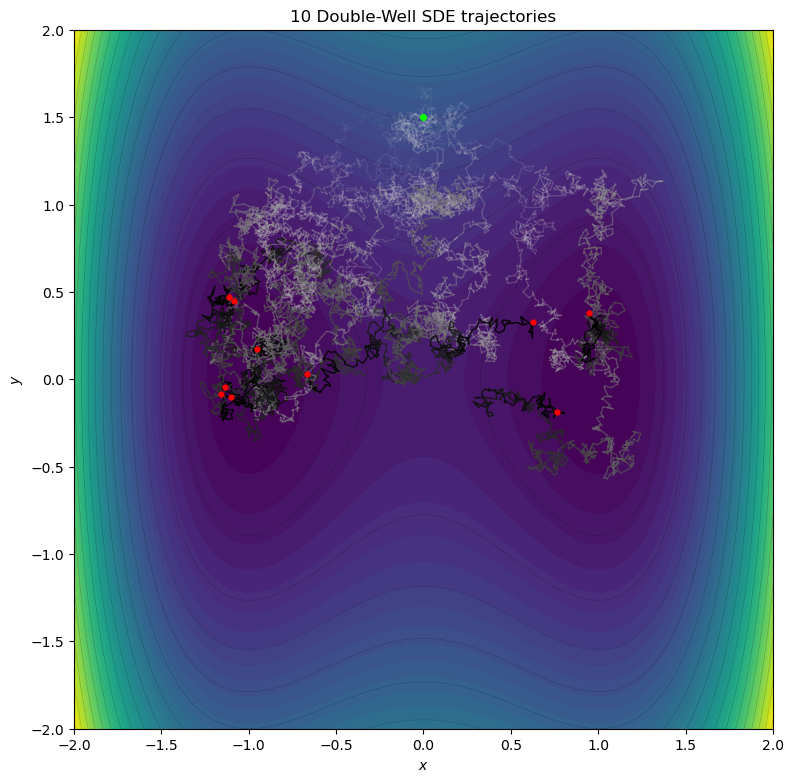

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------
M = 10                       # number of trajectories
x0 = np.array([0.0, 1.5])    # common initial condition

# Same initial condition for every trajectory
X = np.tile(x0, (M, 1))

# Simulate
Y = DW.simulate(X, seed=1)

# ------------------------------------------------------------
# Background potential
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)
Xg, Yg = np.meshgrid(x, y)

Vg = (Xg**2 - 1)**2 + Yg**2

cf = ax.contourf(
    Xg, Yg, Vg,
    levels=50,
    cmap="viridis"
)

ax.contour(
    Xg, Yg, Vg,
    levels=20,
    colors="k",
    linewidths=0.3,
    alpha=0.3
)

# ------------------------------------------------------------
# Draw trajectories
# ------------------------------------------------------------
for m in range(M):

    xtraj = Y[:1000, m, 0]
    ytraj = Y[:1000, m, 1]

    points = np.column_stack([xtraj, ytraj]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    t = np.linspace(0, 1, len(segments))

    # white -> black
    gray = 1 - t

    # alpha 0.15 -> 1
    alpha = t

    colors = np.column_stack([
        gray,
        gray,
        gray,
        alpha
    ])

    lc = LineCollection(
        segments,
        colors=colors,
        linewidth=1,
        capstyle="round"
    )

    ax.add_collection(lc)

    # start/end markers
    ax.scatter(
        xtraj[0], ytraj[0],
        color="lime",
        s=12,
        zorder=5
    )

    ax.scatter(
        xtraj[-1], ytraj[-1],
        color="red",
        s=12,
        zorder=5
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------
ax.set_aspect("equal")
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)

ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title(f"{M} Double-Well SDE trajectories")

plt.tight_layout()
plt.show()

## Numerical Method

### Ulam method

In [7]:
# ----------------------------
# Domain
# ----------------------------
xmin, xmax = -2, 2

# Number of boxes per dimension
Nx = 50
Ny = 50

N_grid = [Nx, Ny]

# Samples per box
n_per_box = 100

Domain = [[xmin, xmax],[xmin, xmax]]

Nt = 1000

In [8]:
ulam = sys.modules["ulam"].Ulam(Domain, N=N_grid, n_per_box=n_per_box)
X = ulam.sample_points()
Y = DW.simulate_fast(
    x0=X,
    show_progress=True
)

Simulating fast: 100%|██████████| 10000/10000 [04:16<00:00, 39.01it/s]


In [9]:
P = ulam.setup(X=X,Y=Y)

Building Ulam matrix (fast): 100%|██████████| 250000/250000 [00:15<00:00, 16600.87it/s]


### EDMD method

In [10]:
M = sys.modules["function_dictionary"].Monomials(10, TotalDegree=True, dim=2)
edmd_M = sys.modules["edmd"].EDMD()
edmd_M.setup(X, Y, M)

Setting up psi vector...
Setting up PSI matrix...
Setting up A & G matrix...


100%|██████████| 250000/250000 [01:16<00:00, 3267.68it/s]

G condition number: 298369116.8394678
Computing operators...
Difference between direct or indirect computation of Perron Frobenius
3.5043896049886863e-06
Computing eigenvalues, eigenvectors and eigenfunctions...


In [11]:
n_plot = 3

models = {
    "EDMD Monomials": edmd_M,
    "ULAM": ulam,
}

import pandas as pd

rows = []
for k in range(n_plot):
    row = {"mode_index": k}

    for name, model in models.items():
        row[f"{name}_K"] = model.K_dict["eigenvalue"][k].real
        row[f"{name}_P"] = model.P_dict["eigenvalue"][k].real

    rows.append(row)

eig_table = pd.DataFrame(rows)
print(eig_table.head())

   mode_index  EDMD Monomials_K  EDMD Monomials_P    ULAM_K    ULAM_P
0           0          1.000000          1.000000  1.000000  1.000000
1           1          0.756405          0.756405  0.757052  0.757052
2           2          0.006783          0.006783  0.094549  0.094549


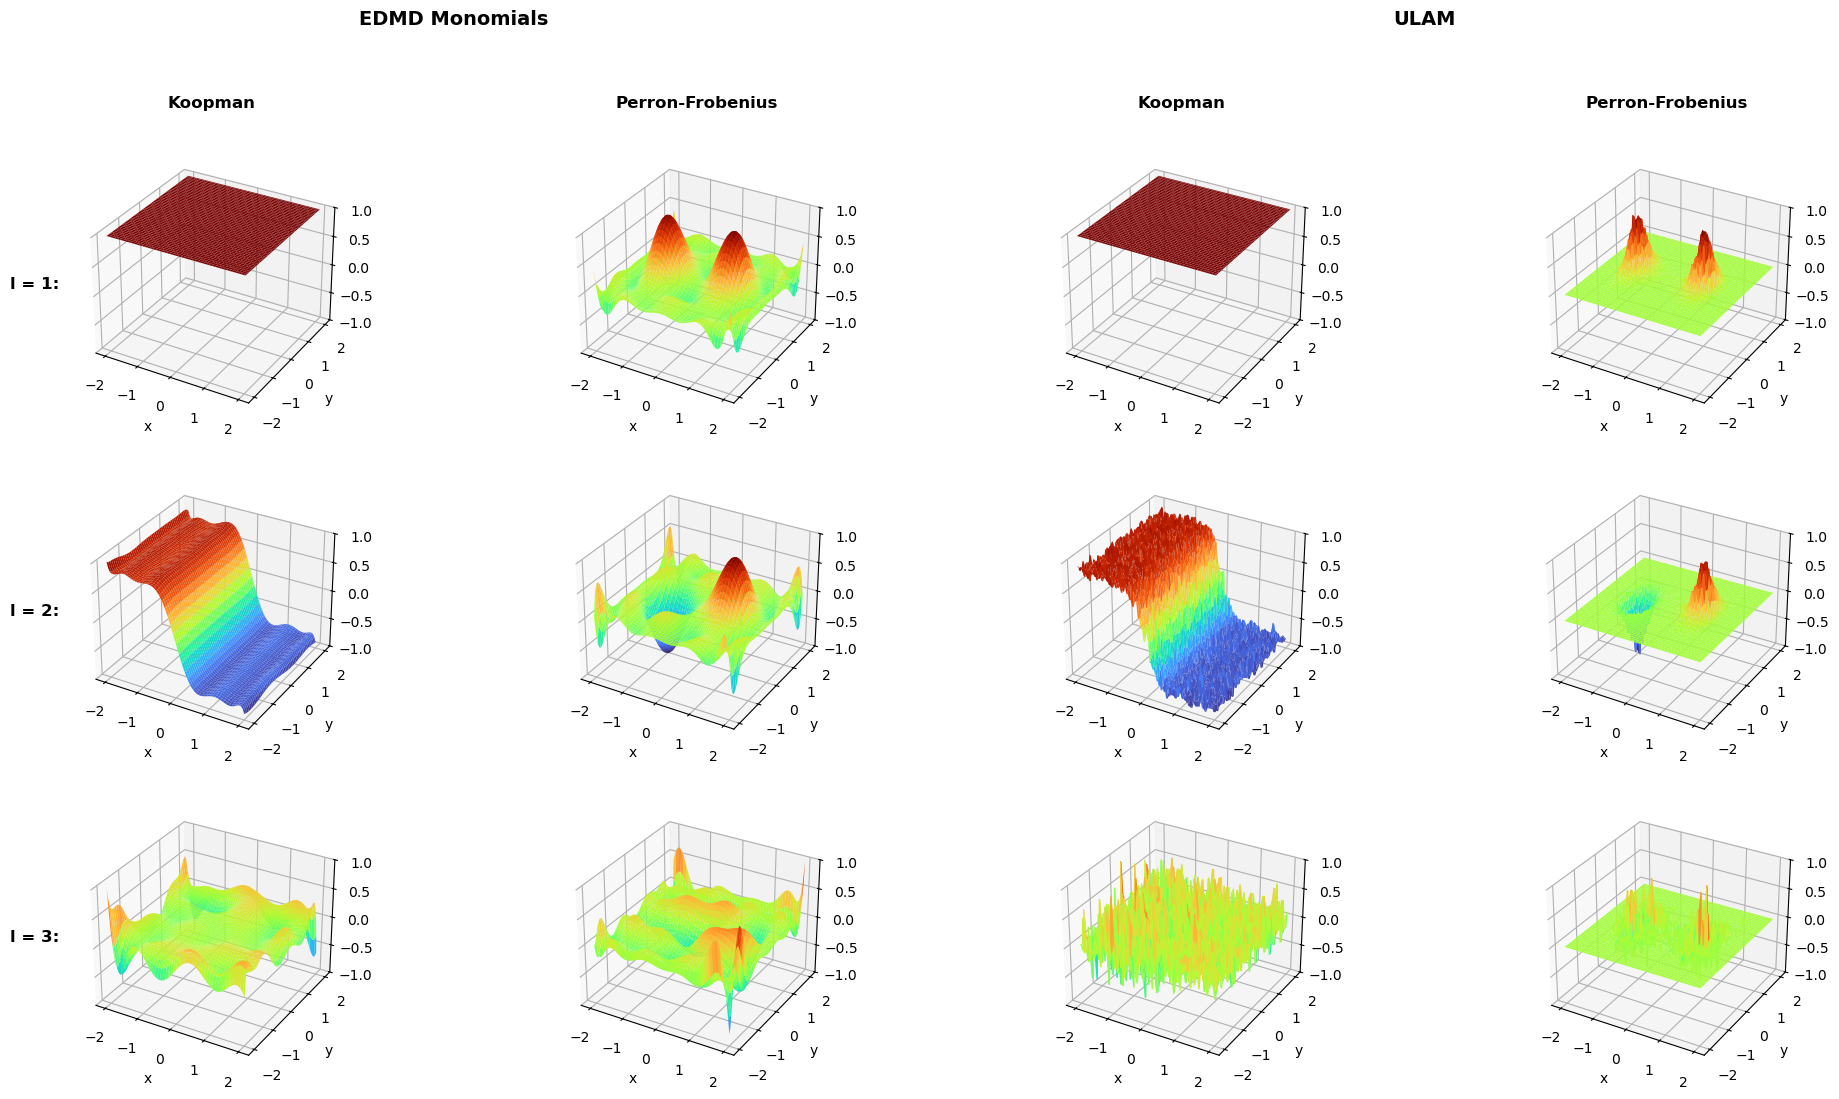

In [17]:

n_plot = 3

models = {
    "EDMD Monomials": edmd_M,
    "ULAM": ulam,
}

modes = ["Koopman","Perron-Frobenius"]  # Koopman + Perron-Frobenius

# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------
Domain = [[-2, 2], [-2, 2]]
points = [100, 100]

x = np.linspace(*Domain[0], points[0])
y = np.linspace(*Domain[1], points[1])

Xg, Yg = np.meshgrid(x, y)
grid = np.column_stack([Xg.ravel(), Yg.ravel()])

fig, axes = plt.subplots(
    n_plot,
    len(models) * len(modes),
    figsize=(6 * len(models) * len(modes), 4 * n_plot),
    subplot_kw={"projection": "3d"}
)

if n_plot == 1:
    axes = axes.reshape(1, -1)

col_labels = []
for name in models.keys():
    for mode in modes:
        col_labels.append((name, mode))

for k in range(n_plot):

    col = 0

    for name, model in models.items():
        for mode in modes:

            f = (
                model.K_dict["eigenfunction"][k]
                if mode == "Koopman"
                else model.P_dict["eigenfunction"][k]
            )

            Z = np.array([f(p) for p in grid]).real
            Z = Z.reshape(points[1], points[0])

            Z /= (np.max(np.abs(Z)) + 1e-12)

            if np.max(Z) + 0.1 < np.max(-Z):
                Z = -Z

            ax = axes[k, col]
            ax.plot_surface(
                Xg, Yg, Z,
                cmap="turbo",
                edgecolor="none",
                vmin=-1,
                vmax=1
            )

            ax.set_title("")

            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_zlabel("")
            ax.set_zlim(-1, 1)
            ax.grid(alpha=0.5)

            col += 1


fig.canvas.draw()
n_cols = len(models) * len(modes)

for j, (name, mode) in enumerate(col_labels):
    ax = axes[0, j]
    ax.text2D(
        0.5, 1.15,
        mode,
        transform=ax.transAxes,
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

fig.canvas.draw()  # make sure positions are finalized

for i, name in enumerate(models.keys()):
    start = i * len(modes)
    end = start + len(modes)

    # get actual axes positions
    left_ax = axes[0, start]
    right_ax = axes[0, end - 1]

    bbox_l = left_ax.get_position()
    bbox_r = right_ax.get_position()

    x_center = (bbox_l.x0 + bbox_r.x1) / 2
    y_top = bbox_l.y1 + 0.1  # small offset above plots

    fig.text(
        x_center,
        y_top,
        name,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold"
    )

for k in range(n_plot):
    ax = axes[k, 0]
    ax.text2D(
        -0.15, 0.5,
        rf"l = {k+1}:",
        transform=ax.transAxes,
        va="center",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

## Apply Perron--Frobenius Operator

In [13]:
import numpy as np

def gaussian_2d_pdf(x, y, mu=(0.0, 0.0), sigma=1.0):
    """
    2D Gaussian PDF with mean mu and covariance sigma^2 I.
    
    Parameters
    ----------
    x, y : array-like or scalars
        Coordinates
    mu : tuple
        Mean (mu_x, mu_y)
    sigma : float
        Standard deviation (isotropic)

    Returns
    -------
    pdf : array-like
        Probability density value(s)
    """

    mu_x, mu_y = mu

    norm = 1.0 / (2.0 * np.pi * sigma**2)

    dx = x - mu_x
    dy = y - mu_y

    exponent = -(dx**2 + dy**2) / (2.0 * sigma**2)

    return norm * np.exp(exponent)

In [14]:
import numpy as np

# -------------------------
# Monte Carlo samples
# -------------------------
Nmc = 250_000

mu = np.array([0.0, 0.0])
sigma = 1.0

# Sample from initial Gaussian
X0 = np.random.normal(
    loc=mu,
    scale=sigma,
    size=(Nmc, 2)
)

# Propagate particles
Y_particles = DW.simulate_fast(
    x0=X0,
    show_progress=True
)

H, xedges, yedges = np.histogram2d(
    Y_particles[:,0],
    Y_particles[:,1],
    bins=[Nx, Ny],
    range=[[xmin, xmax], [xmin, xmax]],
    density=True
)

# histogram2d returns (Nx,Ny)
rho_mc = H

rho_mc /= np.sum(rho_mc) * (xedges[1] - xedges[0]) * (yedges[1] - yedges[0])

# Grid for plotting
xc = 0.5*(xedges[:-1] + xedges[1:])
yc = 0.5*(yedges[:-1] + yedges[1:])
Xmc, Ymc = np.meshgrid(xc, yc, indexing="xy")

Simulating fast: 100%|██████████| 10000/10000 [04:05<00:00, 40.66it/s]


In [15]:
def build_grid(bounds, N):
    """
    bounds: [(a1,b1), (a2,b2), ...]
    N: [N1, N2, ...]
    """

    axes = [
        np.linspace(a, b, n)
        for (a, b), n in zip(bounds, N)
    ]

    mesh = np.meshgrid(*axes, indexing="xy")

    grid = np.stack(mesh, axis=-1).reshape(-1, len(bounds))

    return grid, mesh

grid, (X, Y) = build_grid(
    bounds=[(xmin, xmax), (xmin, xmax)],
    N=[Nx, Ny]
)

print(grid.shape)

rho = gaussian_2d_pdf(X, Y)

rho_ulam = ulam.apply_P(rho)
dx = x[1] - x[0]
dy = y[1] - y[0]

print(np.sum(rho_mc) * dx * dy)

#rho_ulam /= np.sum(rho_ulam) * dx * dy
print(np.sum(rho_ulam) * dx * dy)

rho_edmd = edmd_M.apply_P(rho,grid).reshape(Nx,Ny)
print(np.sum(rho_edmd) * dx * dy)
#rho_edmd /= np.sum(rho_edmd) * dx * dy

(2500, 2)
0.25507601265177016
0.22519890106112406
0.0016324864809713325


C:\Users\wagne\AppData\Local\Temp\ipykernel_28272\1134301462.py:67: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


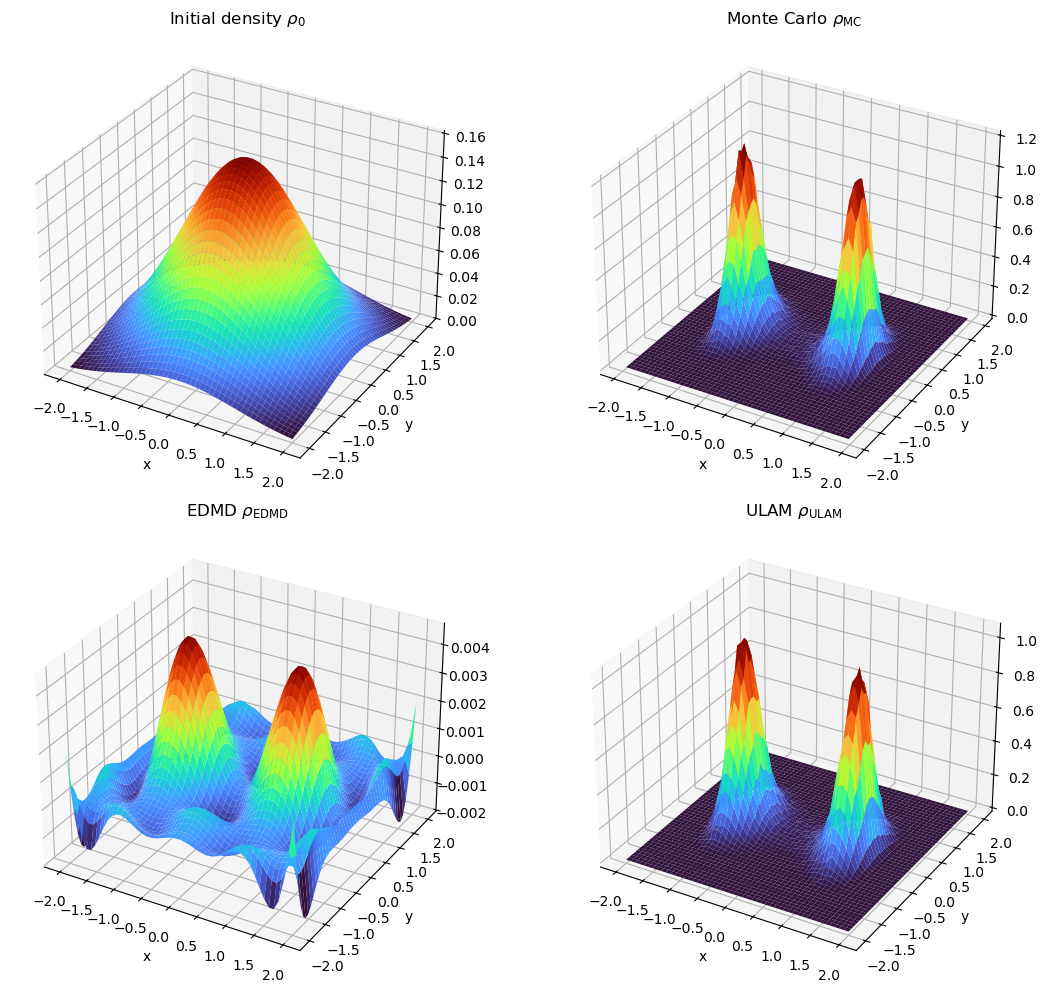

In [16]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 10),constrained_layout=True)

# -------------------------
# 1. Initial PDF (top-left)
# -------------------------
ax1 = fig.add_subplot(2, 2, 1, projection='3d')
ax1.plot_surface(
    X, Y, rho,
    cmap='turbo',
    edgecolor='none'
)
ax1.set_title("Initial density")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
#ax1.set_zlabel(r"Density $\rho_0(x,y)$")

# -------------------------
# 2. Monte Carlo (top-right)
# -------------------------
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
ax2.plot_surface(
    Xmc, Ymc, rho_mc.T,
    cmap='turbo',
    edgecolor='none'
)
ax2.set_title("Monte Carlo")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
#ax2.set_zlabel(r"Density $\rho_{\mathrm{MC}}(x,y)$")

# -------------------------
# 3. EDMD (bottom-left)
# -------------------------
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.plot_surface(
    X, Y, rho_edmd,
    cmap='turbo',
    edgecolor='none'
)
ax3.set_title("EDMD")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
#ax3.set_zlabel(r"Density $\rho_{\mathrm{EDMD}}(x,y)$")

# -------------------------
# 4. ULAM (bottom-right)
# -------------------------
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.plot_surface(
    X, Y, rho_ulam.T,
    cmap='turbo',
    edgecolor='none'
)
ax4.set_title("ULAM")
ax4.set_xlabel("x")
ax4.set_ylabel("y")
#ax4.set_zlabel(r"Density $\rho_{\mathrm{ULAM}}(x,y)$")

ax1.set_title(r"Initial density $\rho_0$")
ax2.set_title(r"Monte Carlo $\rho_{\mathrm{MC}}$")
ax3.set_title(r"EDMD $\rho_{\mathrm{EDMD}}$")
ax4.set_title(r"ULAM $\rho_{\mathrm{ULAM}}$")

plt.tight_layout()
plt.show()